# Tuberculosis Burden in Africa & the USA — Exploratory Data Analysis

**Domain:** Health · **Geography:** 54 African Union member states + United States

This notebook explores the SQLite warehouse (`data/tb_burden.db`) built by the pipeline
(`ingest → transform → load`). It combines:

| Indicator | Source | Code |
|---|---|---|
| TB incidence per 100k (with uncertainty bounds) | WHO Global Health Observatory | `MDG_0000000020` |
| TB death rate per 100k | World Bank | `SH.TBS.MORT` |
| TB treatment success rate (% new cases) | World Bank | `SH.TBS.CURE.ZS` |
| Current health expenditure (% GDP) | World Bank | `SH.XPD.CHEX.GD.ZS` |

**Questions**
1. How large is the gap in TB burden between Africa and the USA?
2. Which African countries and sub-regions carry the highest burden, and how fast is it falling?
3. How does mortality relate to incidence (case-fatality proxy)?
4. Who meets the WHO 90 % treatment-success target?
5. Does health spending relate to TB outcomes?

In [1]:
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio

# Load plotly.js from CDN so the saved notebook stays small
pio.renderers.default = "notebook_connected"

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# Works whether the notebook is run from the project root or from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DB_PATH = ROOT / "data" / "tb_burden.db"
assert DB_PATH.exists(), f"Database not found at {DB_PATH} - run the pipeline first"
conn = sqlite3.connect(DB_PATH)

summary = pd.read_sql("SELECT * FROM tb_burden_summary", conn)
latest = pd.read_sql("SELECT * FROM v_latest_country_burden", conn)
print(f"tb_burden_summary: {summary.shape[0]:,} rows x {summary.shape[1]} cols")
print(f"Countries: {summary.country_code.nunique()}  |  Years: {summary.year.min()}-{summary.year.max()}")
summary.head()

tb_burden_summary: 1,364 rows x 18 cols
Countries: 55  |  Years: 2000-2024


,country_code,country_name,region,sub_region,year,tb_incidence_per_100k,low_estimate,high_estimate,uncertainty_range,burden_category,incidence_yoy_change_pct,tb_mortality_per_100k,case_fatality_ratio_pct,tb_treatment_success_pct,treatment_gap_to_target_pct,meets_treatment_target,health_expenditure_pct_gdp,data_completeness
0,AGO,Angola,Africa,Central,2000,270.0,138.0,737.0,599.0,High,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
1,AGO,Angola,Africa,Central,2001,336.0,178.0,860.0,682.0,Very High,24.44,NaN,NaN,NaN,NaN,NaN,NaN,1
2,AGO,Angola,Africa,Central,2002,390.0,211.0,959.0,748.0,Very High,16.07,NaN,NaN,NaN,NaN,NaN,NaN,1
3,AGO,Angola,Africa,Central,2003,434.0,238.0,1040.0,802.0,Very High,11.28,NaN,NaN,NaN,NaN,NaN,NaN,1
4,AGO,Angola,Africa,Central,2004,468.0,259.0,1090.0,831.0,Very High,7.83,NaN,NaN,NaN,NaN,NaN,NaN,1


## 1. Data quality overview

Incidence (WHO) covers 2000–2024 for every country, whereas the World Bank mortality and treatment
series cover the most recent ~10 years only (the API was queried with `mrv=10`). Health expenditure
uses `mrv=5`. Missing values are therefore *structural* (coverage windows), not data errors.

In [2]:
completeness = (summary
    .assign(period=np.where(summary.year >= 2015, "2015-2024", "2000-2014"))
    .groupby("period")[["tb_incidence_per_100k", "tb_mortality_per_100k",
                        "tb_treatment_success_pct", "health_expenditure_pct_gdp"]]
    .apply(lambda g: g.notna().mean().mul(100).round(1)))
completeness

,tb_incidence_per_100k,tb_mortality_per_100k,tb_treatment_success_pct,health_expenditure_pct_gdp
period,,,,
2000-2014,100.0,0.0,6.6,0.0
2015-2024,100.0,98.2,87.8,40.0


In [3]:
summary[["tb_incidence_per_100k", "tb_mortality_per_100k", "case_fatality_ratio_pct",
         "tb_treatment_success_pct", "health_expenditure_pct_gdp"]].describe().round(1)

,tb_incidence_per_100k,tb_mortality_per_100k,case_fatality_ratio_pct,tb_treatment_success_pct,health_expenditure_pct_gdp
count,1364.0,540.0,540.0,537.0,220.0
mean,281.4,29.3,14.2,82.1,5.7
std,293.6,26.4,6.1,10.2,2.9
min,2.4,0.2,1.7,25.0,2.3
25%,89.0,10.0,9.6,78.0,3.7
50%,194.5,22.0,14.2,84.0,4.7
75%,378.2,38.0,18.0,89.0,7.0
max,2700.0,181.0,30.0,96.0,18.5


## 2. Africa vs USA — the headline gap

Africa's figure below is the unweighted mean across countries for each year (every country counts
equally, independent of population).

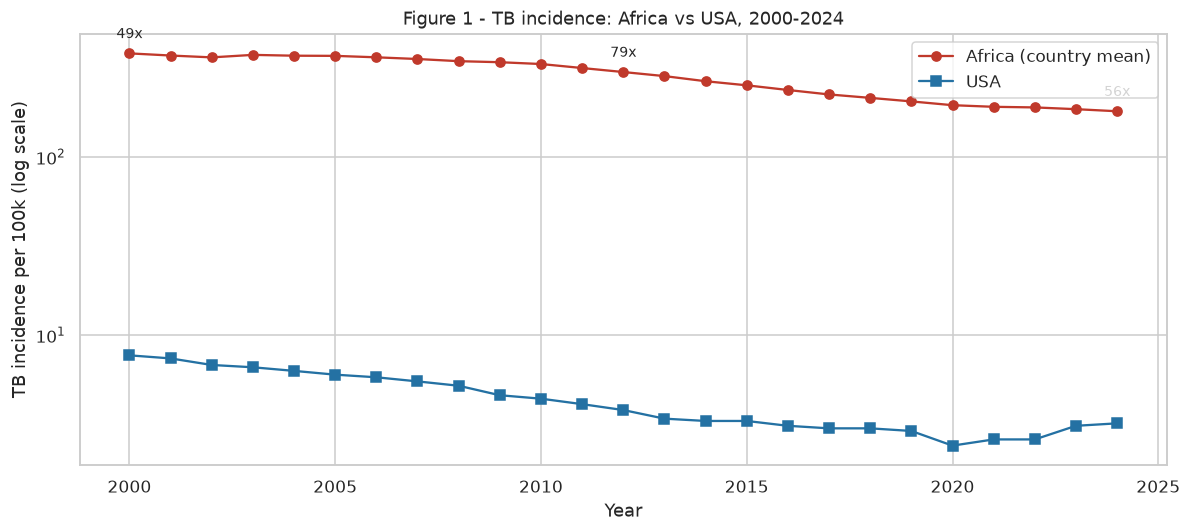

region,Africa,USA,ratio_africa_to_usa
year,,,
2000,380.0,7.7,49.3
2010,331.2,4.4,75.3
2020,194.6,2.4,81.1
2024,180.0,3.2,56.2


In [4]:
trend = (summary.groupby(["region", "year"])["tb_incidence_per_100k"].mean()
                .unstack("region"))
trend["ratio_africa_to_usa"] = trend["Africa"] / trend["USA"]

fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.plot(trend.index, trend["Africa"], marker="o", color="#c0392b", label="Africa (country mean)")
ax1.plot(trend.index, trend["USA"], marker="s", color="#2471a3", label="USA")
ax1.set_yscale("log")
ax1.set_ylabel("TB incidence per 100k (log scale)")
ax1.set_xlabel("Year")
ax1.set_title("Figure 1 - TB incidence: Africa vs USA, 2000-2024")
ax1.legend(loc="upper right")
for yr in (2000, 2012, 2024):
    ax1.annotate(f"{trend.loc[yr, 'ratio_africa_to_usa']:.0f}x", (yr, trend.loc[yr, "Africa"]),
                 textcoords="offset points", xytext=(0, 10), ha="center", fontsize=9)
plt.tight_layout()
plt.show()

trend.loc[[2000, 2010, 2020, 2024]].round(1)

**Finding.** African TB incidence has fallen steadily since the mid-2000s, yet the average African
country still records **50-80x** the US rate (56x in 2024). The USA itself saw a COVID-era dip in 2020
(under-diagnosis) followed by a rebound in 2023–2024 — the US rate is no longer declining.

## 3. Highest-burden African countries (latest year)

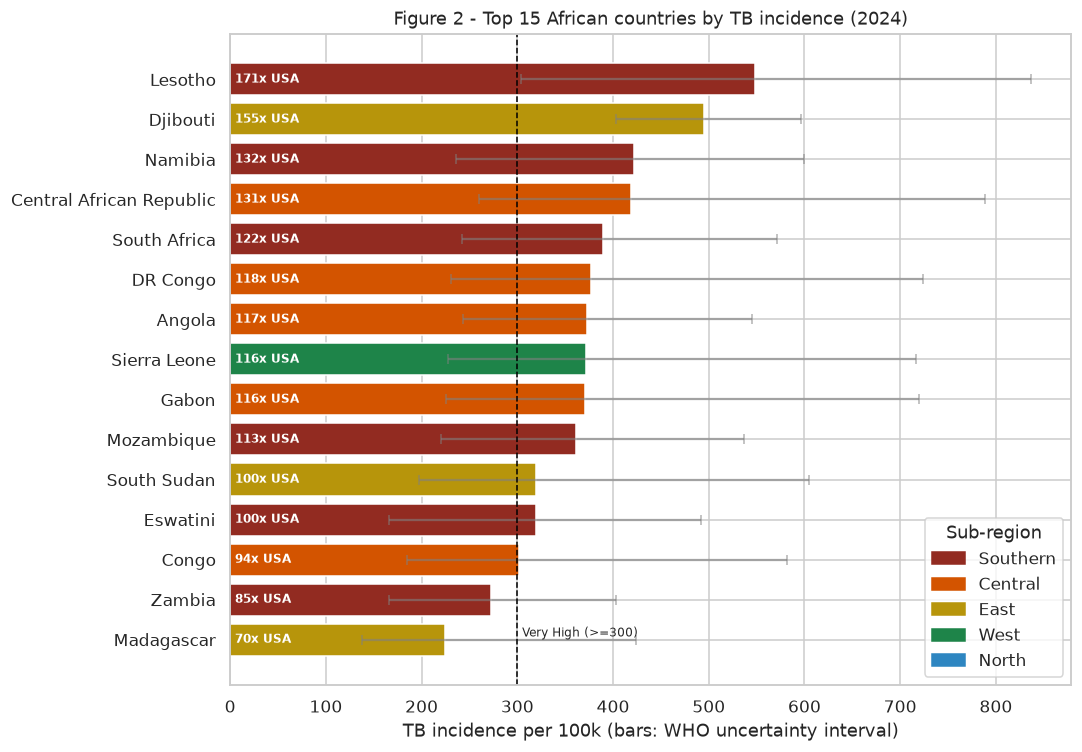

In [5]:
usa_rate = latest.loc[latest.country_code == "USA", "tb_incidence_per_100k"].iloc[0]
top15 = (latest[latest.region == "Africa"]
         .nlargest(15, "tb_incidence_per_100k")
         .sort_values("tb_incidence_per_100k"))

fig, ax = plt.subplots(figsize=(10, 7))
palette = {"Southern": "#922b21", "Central": "#d35400", "East": "#b7950b",
           "West": "#1e8449", "North": "#2e86c1"}
colors = top15["sub_region"].map(palette)
ax.barh(top15["country_name"], top15["tb_incidence_per_100k"], color=colors,
        xerr=[top15["tb_incidence_per_100k"] - top15["low_estimate"],
              top15["high_estimate"] - top15["tb_incidence_per_100k"]],
        error_kw={"ecolor": "grey", "capsize": 3, "alpha": 0.6})
ax.axvline(300, ls="--", color="black", lw=1)
ax.text(305, 0, "Very High (>=300)", fontsize=8, va="bottom")
for y, (val, name) in enumerate(zip(top15["tb_incidence_per_100k"], top15["country_name"])):
    ax.text(5, y, f"{val / usa_rate:.0f}x USA", va="center", color="white", fontsize=8,
            fontweight="bold")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in palette.values()]
ax.legend(handles, palette.keys(), title="Sub-region", loc="lower right")
ax.set_xlabel("TB incidence per 100k (bars: WHO uncertainty interval)")
ax.set_title(f"Figure 2 - Top 15 African countries by TB incidence ({int(latest.year.max())})")
plt.tight_layout()
plt.show()

**Finding.** Southern and Central Africa dominate the top of the table. Lesotho, Djibouti, Namibia,
the Central African Republic and South Africa each exceed **380 per 100k** — more than 100 times
the US rate. Uncertainty intervals are wide (often ±50 %), reflecting modelled rather than fully
notified estimates.

## 4. Sub-regional trends — where is progress fastest?

In [6]:
sub_trend = (summary[summary.region == "Africa"]
             .groupby(["sub_region", "year"], as_index=False)["tb_incidence_per_100k"].mean())
usa_trend = summary[summary.region == "USA"][["sub_region", "year", "tb_incidence_per_100k"]]
sub_trend = pd.concat([sub_trend, usa_trend.replace({"North America": "USA"})])

fig = px.line(sub_trend, x="year", y="tb_incidence_per_100k", color="sub_region",
              markers=True, log_y=True,
              labels={"tb_incidence_per_100k": "Mean incidence per 100k (log)",
                      "year": "Year", "sub_region": "Sub-region"},
              title="Figure 3 - TB incidence by African sub-region vs USA (interactive)")
fig.update_layout(height=480, hovermode="x unified")
fig.show()

pivot = sub_trend.pivot(index="sub_region", columns="year", values="tb_incidence_per_100k")
change = ((pivot[2024] - pivot[2010]) / pivot[2010] * 100).round(1).sort_values()
change.rename("pct_change_2010_2024").to_frame()

,pct_change_2010_2024
sub_region,
Southern,-61.0
East,-46.0
West,-30.9
Central,-27.3
USA,-27.3
North,-25.1


**Finding.** Southern Africa — the epicentre of the TB/HIV syndemic — has achieved the steepest
decline since 2010 as antiretroviral therapy scaled up, followed by East Africa. West and
Central Africa have improved far more slowly (-31 % and -27 %), and North Africa — already at a
moderate level — shows the smallest relative decline (-25 %), with a slight uptick after 2020.

## 5. Mortality vs incidence — the case-fatality proxy

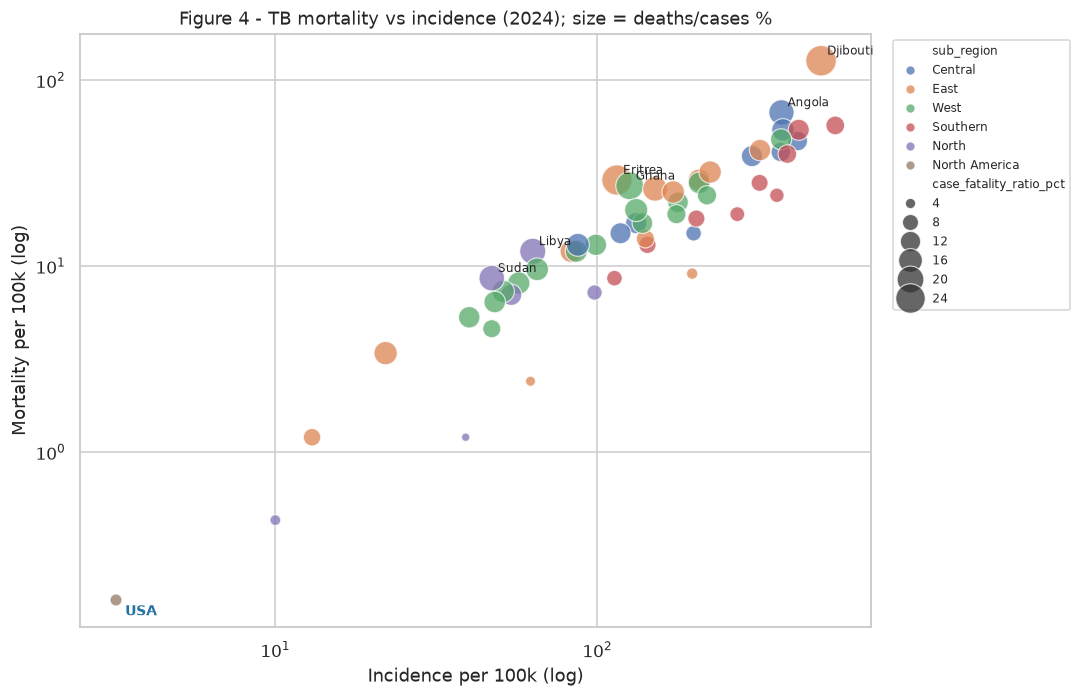

,mean,50%,min,max
region,,,,
Africa,12.4,12.9,3.1,25.7
USA,5.0,5.0,5.0,5.0


In [7]:
recent = summary.dropna(subset=["tb_incidence_per_100k", "tb_mortality_per_100k"])
recent = recent[recent.year == recent.year.max()]

fig, ax = plt.subplots(figsize=(10, 6.5))
sns.scatterplot(data=recent, x="tb_incidence_per_100k", y="tb_mortality_per_100k",
                hue="sub_region", size="case_fatality_ratio_pct", sizes=(30, 400),
                alpha=0.75, ax=ax)
ax.set_xscale("log")
ax.set_yscale("log")
for _, r in recent.nlargest(6, "case_fatality_ratio_pct").iterrows():
    ax.annotate(r.country_name, (r.tb_incidence_per_100k, r.tb_mortality_per_100k),
                fontsize=8, xytext=(4, 4), textcoords="offset points")
usa = recent[recent.country_code == "USA"].iloc[0]
ax.annotate("USA", (usa.tb_incidence_per_100k, usa.tb_mortality_per_100k), fontsize=9,
            fontweight="bold", xytext=(6, -10), textcoords="offset points", color="#2471a3")
ax.set_xlabel("Incidence per 100k (log)")
ax.set_ylabel("Mortality per 100k (log)")
ax.set_title(f"Figure 4 - TB mortality vs incidence ({int(recent.year.max())}); size = deaths/cases %")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

cfr = recent.groupby("region")["case_fatality_ratio_pct"].describe()[["mean", "50%", "min", "max"]]
cfr.round(1)

**Finding.** Mortality scales with incidence, but the ratio between them varies widely. Countries
with high deaths-per-case (upper-left of the cloud) point to late diagnosis, HIV co-infection and
weak treatment access. The US ratio is low in absolute terms, while in the worst-affected African
countries deaths reach **up to about a quarter** of estimated cases (Africa range 3-26 %).

## 6. Treatment success vs the WHO 90 % target

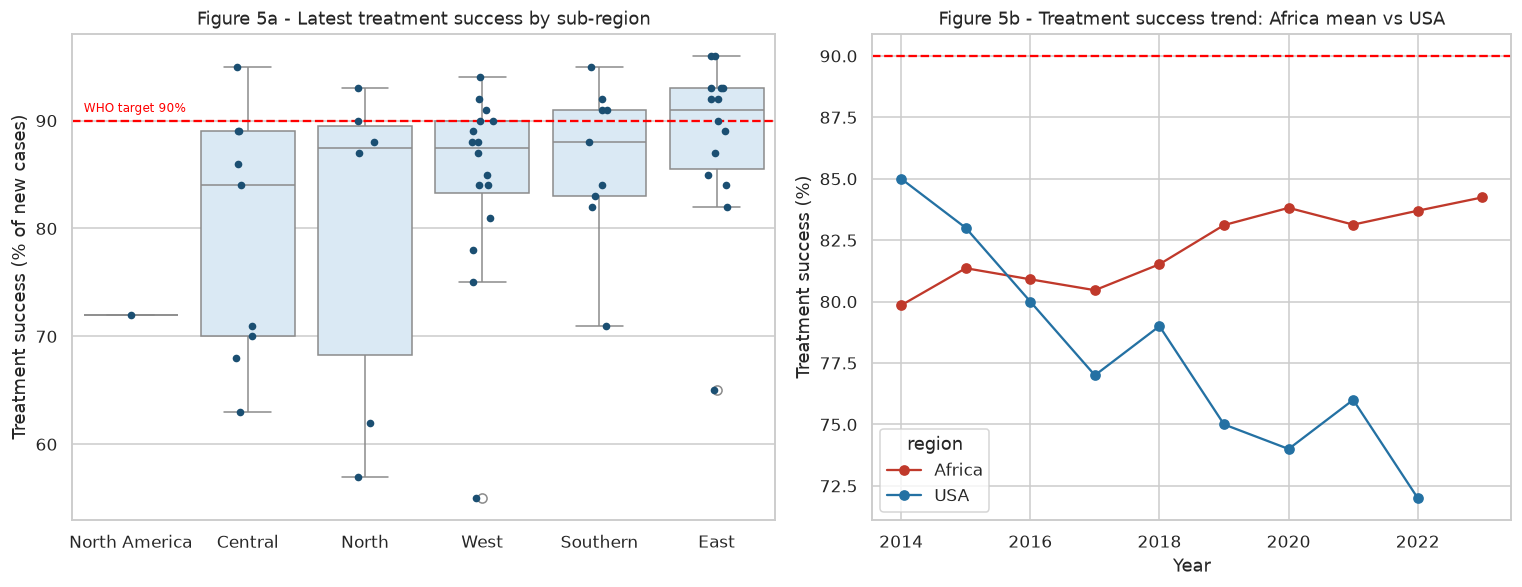

African countries meeting the 90% target: 20 of 54


In [8]:
treat = pd.read_sql("""
    SELECT c.country_name, c.region, c.sub_region, t.year, t.tb_treatment_success_pct
    FROM fact_tb_treatment t JOIN dim_country c USING (country_code)
""", conn)
latest_treat = treat.sort_values("year").groupby("country_name").tail(1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1.1, 1]})
order = (latest_treat.groupby("sub_region")["tb_treatment_success_pct"].median()
         .sort_values().index)
sns.boxplot(data=latest_treat, x="sub_region", y="tb_treatment_success_pct", order=order,
            ax=axes[0], color="#d6eaf8")
sns.stripplot(data=latest_treat, x="sub_region", y="tb_treatment_success_pct", order=order,
              ax=axes[0], color="#1b4f72", size=5)
axes[0].axhline(90, ls="--", color="red")
axes[0].text(-0.4, 90.8, "WHO target 90%", color="red", fontsize=8)
axes[0].set_title("Figure 5a - Latest treatment success by sub-region")
axes[0].set_xlabel("")
axes[0].set_ylabel("Treatment success (% of new cases)")

yearly = treat.groupby(["region", "year"])["tb_treatment_success_pct"].mean().unstack("region")
yearly.plot(ax=axes[1], marker="o", color={"Africa": "#c0392b", "USA": "#2471a3"})
axes[1].axhline(90, ls="--", color="red")
axes[1].set_title("Figure 5b - Treatment success trend: Africa mean vs USA")
axes[1].set_ylabel("Treatment success (%)")
axes[1].set_xlabel("Year")
plt.tight_layout()
plt.show()

africa_treat = latest_treat[latest_treat.region == "Africa"]
n_meet = int((africa_treat.tb_treatment_success_pct >= 90).sum())
print(f"African countries meeting the 90% target: {n_meet} of {len(africa_treat)}")

**Finding.** A striking reversal: on *treatment outcomes* many African programmes outperform the
USA. Roughly a third of African countries meet the 90 % WHO target, while the US success rate
(~72 %) sits well below it — largely because US cohorts include more patients who die from
comorbidities, transfer out or are lost to follow-up, and outcome reporting is stricter.

## 7. Health expenditure and TB burden

In [9]:
hx = summary.dropna(subset=["health_expenditure_pct_gdp", "tb_incidence_per_100k"])
hx = hx.sort_values("year").groupby("country_code").tail(1)

fig = px.scatter(hx, x="health_expenditure_pct_gdp", y="tb_incidence_per_100k",
                 color="sub_region", hover_name="country_name", log_y=True,
                 size=hx["tb_mortality_per_100k"].fillna(1).clip(lower=1),
                 labels={"health_expenditure_pct_gdp": "Current health expenditure (% of GDP)",
                         "tb_incidence_per_100k": "TB incidence per 100k (log)"},
                 title="Figure 6 - Health spending vs TB incidence (latest year with both)")
fig.update_layout(height=500)
fig.show()

rho = hx[["health_expenditure_pct_gdp", "tb_incidence_per_100k",
          "tb_treatment_success_pct"]].corr(method="spearman").round(2)
rho

,health_expenditure_pct_gdp,tb_incidence_per_100k,tb_treatment_success_pct
health_expenditure_pct_gdp,1.00,-0.05,-0.12
tb_incidence_per_100k,-0.05,1.00,0.10
tb_treatment_success_pct,-0.12,0.10,1.00


**Finding.** Spending as a share of GDP is essentially unrelated (Spearman ρ ≈ -0.05) to TB incidence across Africa —
Lesotho and Namibia spend relatively high shares of GDP yet carry very high burdens, because the
drivers are HIV prevalence, mining-related transmission and absolute per-capita resources rather
than GDP share. The USA (≈17 % of GDP) is an outlier in both spending and low burden.

## 8. Correlation heatmap of country-level indicators

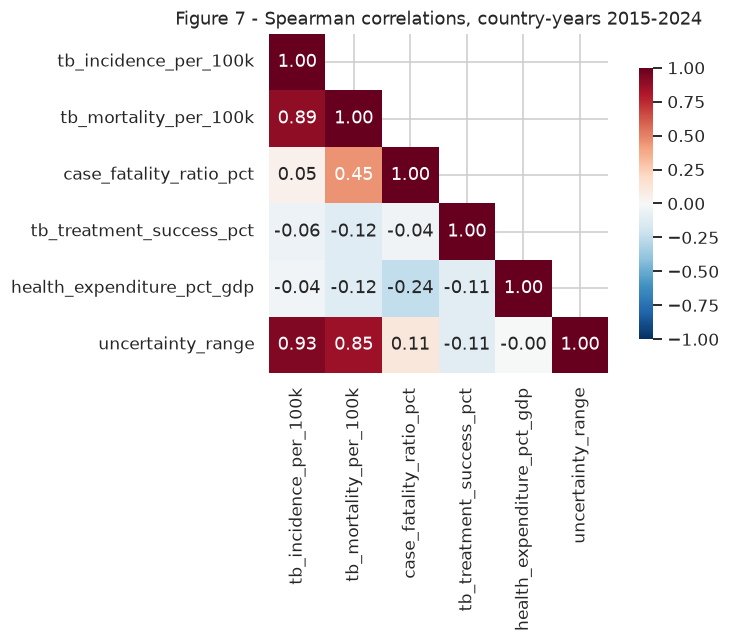

In [10]:
cols = ["tb_incidence_per_100k", "tb_mortality_per_100k", "case_fatality_ratio_pct",
        "tb_treatment_success_pct", "health_expenditure_pct_gdp", "uncertainty_range"]
corr = summary[summary.year >= 2015][cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(8, 6))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            square=True, ax=ax, cbar_kws={"shrink": 0.8})
ax.set_title("Figure 7 - Spearman correlations, country-years 2015-2024")
plt.tight_layout()
plt.show()

## 9. Burden-category migration, 2000 → 2024

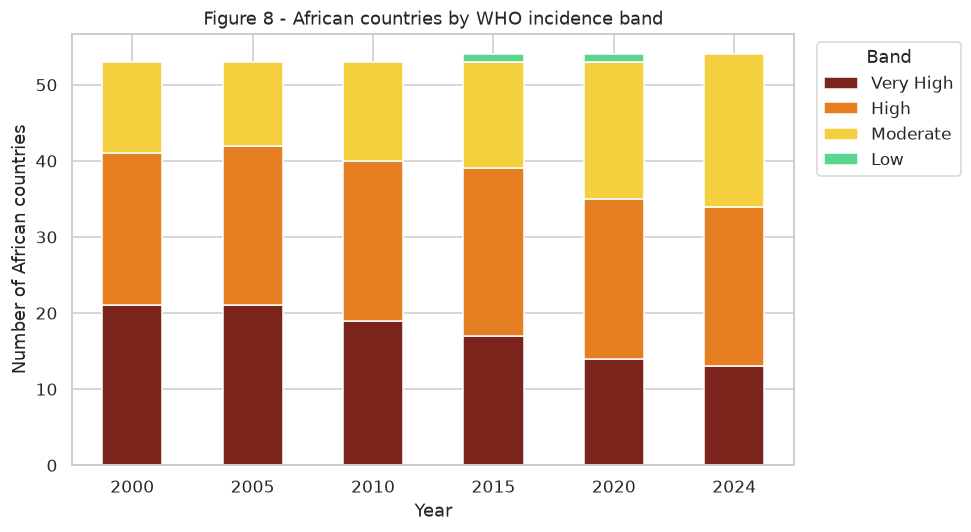

burden_category,Very High,High,Moderate,Low
year,,,,
2000,21,20,12,0
2005,21,21,11,0
2010,19,21,13,0
2015,17,22,14,1
2020,14,21,18,1
2024,13,21,20,0


In [11]:
bands = (summary[(summary.region == "Africa") & summary.year.isin([2000, 2005, 2010, 2015, 2020, 2024])]
         .pivot_table(index="year", columns="burden_category", values="country_code",
                      aggfunc="count", fill_value=0)
         .reindex(columns=["Very High", "High", "Moderate", "Low"], fill_value=0))
ax = bands.plot(kind="bar", stacked=True, figsize=(9, 5),
                color=["#7b241c", "#e67e22", "#f4d03f", "#58d68d"])
ax.set_ylabel("Number of African countries")
ax.set_xlabel("Year")
ax.set_title("Figure 8 - African countries by WHO incidence band")
ax.legend(title="Band", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
bands

## 10. Summary of insights

1. **A 50-80x gap.** The average African country's TB incidence was 56 times the US rate in 2024; the
   worst-affected (Lesotho, Djibouti, Namibia, CAR, South Africa) are 120–170x higher.
2. **Real but uneven progress.** Southern and East Africa have cut incidence sharply since 2010
   (Botswana, South Africa and Eswatini by >60 % in a decade). Central and West Africa lag.
3. **"Very High" burden is shrinking.** The number of African countries above 300/100k fell from
   21 in 2000 to 13 in 2024 — still a quarter of the continent.
4. **Deaths per case vary greatly.** Case-fatality proxies range from ~3 % to ~26 % across Africa,
   flagging diagnostic and treatment-access gaps.
5. **Treatment outcomes invert the picture.** 20 of 54 African countries meet the 90 % success
   target while the USA reports ~72 %.
6. **The USA is not on a downward path.** US incidence rebounded after 2020 to 3.2/100k in 2024.
7. **Spending share alone does not explain burden** — targeted TB/HIV programmes matter more than
   health expenditure as % of GDP.

*Limitations:* Africa aggregates are unweighted country means (not population-weighted); WHO
incidence values are modelled estimates with wide uncertainty; World Bank series cover only the
last 5–10 years.

In [12]:
conn.close()